In [2]:
import ee
import geemap

ee.Authenticate()
ee.Initialize()

Enter verification code:  4/1AXlqoi7UVJxasVYo0Nnje1FWtjRVGsCqhP6wMVZggcEiGrGMBYrIIaTnDH0



Successfully saved authorization token.


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [1]:
import ee
import geemap
ee.Initialize(project="sentinel5p-monitor-506602") #Connecting to the GEE Server

In [2]:
import geopandas as gpd

gdf = gpd.read_file("Datasets\pakistan_tehsil_data.geojson")

In [3]:
punjab_gdf = gdf[gdf["adm1_name"] == "Punjab"].copy()
filtered_columns = ["adm1_name", "adm2_name", "adm3_name", "geometry"]
punjab_gdf = punjab_gdf[filtered_columns]
punjab_gdf = punjab_gdf.rename(columns={"adm1_name" : "province", "adm2_name" : "district", "adm3_name" : "tehsil"})   

In [4]:
import requests
import pandas as pd

locations_url = "https://api.openaq.org/v3/locations"
my_badge = {"X-API-Key": "6090bce23cada7104a6dde39d950d109ce271cccb7de1a7b69aaa2ee79f9d9f1"}

scout_instructions = {
    "iso": "PK",  
    "limit": 100
}

response = requests.get(locations_url, params=scout_instructions, headers=my_badge)
data = response.json()

if "results" in data and len(data["results"]) > 0:
    locations_df = pd.json_normalize(data["results"])
    print(locations_df.columns.tolist())
    print("\n", locations_df[['name', 'locality']].head())
else:
    print("Empty.")

['id', 'name', 'locality', 'timezone', 'isMobile', 'isMonitor', 'instruments', 'sensors', 'licenses', 'bounds', 'distance', 'country.id', 'country.code', 'country.name', 'owner.id', 'owner.name', 'provider.id', 'provider.name', 'coordinates.latitude', 'coordinates.longitude', 'datetimeFirst.utc', 'datetimeFirst.local', 'datetimeLast.utc', 'datetimeLast.local']

                             name   locality
0                       Peshawar        N/A
1                        Karachi        N/A
2  US Diplomatic Post: Islamabad  Islamabad
3     US Diplomatic Post: Lahore     Lahore
4                      Islamabad        N/A


In [5]:
for index, row in locations_df.iterrows():
    print(f"\nStation Name: {row['name']}")
    print(f"Location ID: {row['id']}")
    print("--- Sensors Plugged In ---")

    sensors = row["sensors"]

    if isinstance(sensors, list):
        for device in sensors:
            param_name = device["parameter"]["name"]
            sensor_id = device["id"]
            print(f"Sensor ID: {sensor_id} --> Measures: {param_name}")
    else:
        print("No sensors found at this station.")


Station Name: Peshawar
Location ID: 8088
--- Sensors Plugged In ---
Sensor ID: 23455 --> Measures: pm25

Station Name: Karachi
Location ID: 8156
--- Sensors Plugged In ---
Sensor ID: 23747 --> Measures: pm25

Station Name: US Diplomatic Post: Islamabad
Location ID: 8634
--- Sensors Plugged In ---
Sensor ID: 25066 --> Measures: pm25

Station Name: US Diplomatic Post: Lahore
Location ID: 8664
--- Sensors Plugged In ---
Sensor ID: 25135 --> Measures: pm25

Station Name: Islamabad
Location ID: 233470
--- Sensors Plugged In ---
Sensor ID: 1343270 --> Measures: pm25

Station Name: Karachi, Pakistan
Location ID: 1894633
--- Sensors Plugged In ---
Sensor ID: 7466368 --> Measures: pm1
Sensor ID: 7466369 --> Measures: pm10
Sensor ID: 7466370 --> Measures: pm25
Sensor ID: 7466372 --> Measures: temperature
Sensor ID: 7466371 --> Measures: temperature

Station Name: Lahore
Location ID: 1894641
--- Sensors Plugged In ---
Sensor ID: 7466363 --> Measures: pm1
Sensor ID: 7466364 --> Measures: pm10
Sen

In [6]:
import time
punjab_targets = {
    "Lahore_JoharTown": 13191315,
    "Multan_Industrial": 14182582,
    "Sialkot_DCOffice": 13248051,
    "Bahawalpur_PHA": 13367550,
    "Rawalpindi_WomenUniv": 13181992
}
all_city_records = []

for city_name, sensor_id in punjab_targets.items():
    print(f"Fetching data for {city_name} with the Sensor ID: {sensor_id}")
    url = f"https://api.openaq.org/v3/sensors/{sensor_id}/measurements"
    params = {
        "datetime_from": "2025-09-01T00:00:00+05:00",
        "datetime_to": "2025-11-30T23:59:59+05:00",
        "limit": 1000
    }
    response = requests.get(url, params=params, headers=my_badge)
    data = response.json()
    if "results" in data and len(data["results"]) > 0:
        df_temp = pd.json_normalize(data["results"])
        df_temp["station_label"] = city_name
        all_city_records.append(df_temp)
    else:
        print(f"No readings returned.")

    time.sleep(1)

if all_city_records:
    ground_truth_df = pd.concat(all_city_records, ignore_index=True)
    print("\n--- Pipeline Complete ---")
    print(f"Total PM2.5 measurements gathered: {len(ground_truth_df)}")
    print(ground_truth_df[['station_label', 'value', 'period.datetimeFrom.local']].head(10))

Fetching data for Lahore_JoharTown with the Sensor ID: 13191315
Fetching data for Multan_Industrial with the Sensor ID: 14182582
Fetching data for Sialkot_DCOffice with the Sensor ID: 13248051
No readings returned.
Fetching data for Bahawalpur_PHA with the Sensor ID: 13367550
Fetching data for Rawalpindi_WomenUniv with the Sensor ID: 13181992

--- Pipeline Complete ---
Total PM2.5 measurements gathered: 4000
      station_label      value  period.datetimeFrom.local
0  Lahore_JoharTown  33.337875  2025-09-01T00:00:00+05:00
1  Lahore_JoharTown  33.711917  2025-09-01T01:00:00+05:00
2  Lahore_JoharTown  34.158333  2025-09-01T02:00:00+05:00
3  Lahore_JoharTown  28.736791  2025-09-01T03:00:00+05:00
4  Lahore_JoharTown  30.561916  2025-09-01T04:00:00+05:00
5  Lahore_JoharTown   9.373708  2025-09-01T05:00:00+05:00
6  Lahore_JoharTown   5.892417  2025-09-01T06:00:00+05:00
7  Lahore_JoharTown  14.954833  2025-09-01T07:00:00+05:00
8  Lahore_JoharTown   6.996917  2025-09-01T08:00:00+05:00
9  Lahor

In [7]:
aerosol_data = ee.ImageCollection("COPERNICUS/S5P/NRTI/L3_AER_AI")   #Utilizing European Sentinel-5p Satellite
smog_season_images = aerosol_data.filterDate('2025-09-01', '2025-11-30')
image_count = smog_season_images.size().getInfo()
print(f"Total satellite images found: {image_count}")

Total satellite images found: 18140


In [8]:
lahore_pin = ee.Geometry.Point([74.2955, 31.4697])
lahore_images = smog_season_images.filterBounds(lahore_pin)
aod_data = lahore_images.select('absorbing_aerosol_index')
lahore_count = aod_data.size().getInfo()
print(f"Total satellite images hovering over Lahore: {lahore_count}")


Total satellite images hovering over Lahore: 247


In [9]:
def extract_space_data(Image):
    pixel_value = Image.reduceRegion(
        reducer = ee.Reducer.first(),
        geometry = lahore_pin,
        scale = 1000
    )
    date = Image.date().format("YYYY-MM-dd")
    return ee.Feature(None, {
        'date': date,
        'aerosol_index': pixel_value.get('absorbing_aerosol_index')
    })

extracted_data = aod_data.map(extract_space_data).getInfo()

records = []
for item in extracted_data['features']:
    records.append(item['properties'])
satellite_df = pd.DataFrame(records)
print(satellite_df.head(15))

          date  aerosol_index
0   2025-09-01            NaN
1   2025-09-01            NaN
2   2025-09-01            NaN
3   2025-09-01       0.243581
4   2025-09-02            NaN
5   2025-09-02            NaN
6   2025-09-02      -0.016876
7   2025-09-02            NaN
8   2025-09-02            NaN
9   2025-09-02            NaN
10  2025-09-02            NaN
11  2025-09-03      -0.179707
12  2025-09-03            NaN
13  2025-09-03            NaN
14  2025-09-04            NaN


In [10]:
filtered_satellite_df = satellite_df.dropna(subset=["aerosol_index"])
daily_satellite_df = filtered_satellite_df.groupby("date").mean().reset_index()
print(f"Cleaned up {len(satellite_df)} raw images down to {len(daily_satellite_df)} valid daily averages")
print(daily_satellite_df.head(10))

Cleaned up 247 raw images down to 88 valid daily averages
         date  aerosol_index
0  2025-09-01       0.243581
1  2025-09-02      -0.016876
2  2025-09-03      -0.179707
3  2025-09-04      -1.414947
4  2025-09-05       0.003205
5  2025-09-06      -0.472650
6  2025-09-07      -1.133145
7  2025-09-08      -1.262308
8  2025-09-09      -1.523807
9  2025-09-10       0.079949


In [21]:
ground_truth_df["clean_date"] = ground_truth_df['period.datetimeFrom.local'].str[:10]
daily_ground_df = ground_truth_df[ground_truth_df["station_label"] == "Lahore_JoharTown"].groupby("clean_date")["value"].mean().reset_index()
final_table = pd.merge(
    left = daily_satellite_df,
    right = daily_ground_df,
    left_on = "date",
    right_on = "clean_date",
    how = "inner"
)
print(f"Successfully matched {len(final_table)} days of space and ground data!")
print(final_table[['date', 'aerosol_index', 'value']].head(10))
             


Successfully matched 44 days of space and ground data!
         date  aerosol_index      value
0  2025-09-01       0.243581  16.145295
1  2025-09-02      -0.016876  24.063513
2  2025-09-03      -0.179707  45.430094
3  2025-09-04      -1.414947  27.482991
4  2025-09-05       0.003205  54.505825
5  2025-09-06      -0.472650  43.681493
6  2025-09-07      -1.133145  28.436812
7  2025-09-08      -1.262308  48.503461
8  2025-09-09      -1.523807  50.770707
9  2025-09-10       0.079949  48.254081


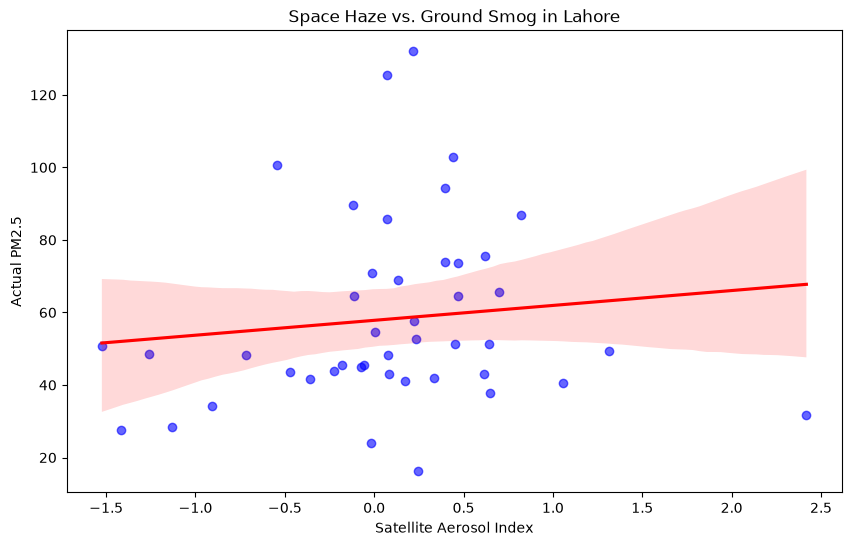

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.regplot(
    data = final_table,
    x = "aerosol_index",
    y = "value",
    scatter_kws = {"alpha": 0.6, "color": "blue"},
    line_kws = {"color": "red"})
plt.title("Space Haze vs. Ground Smog in Lahore")
plt.xlabel("Satellite Aerosol Index")
plt.ylabel("Actual PM2.5")
plt.show()